# PA27 — Data Quality & Exploratory Data Analysis

## 0. Setup

In [1]:
from pathlib import Path
import sys
import math

# ---------------------------------------------------------
# Locate project root
# ---------------------------------------------------------

def find_project_root():
  

    current = Path.cwd().resolve()

    for candidate in [current, *current.parents]:
        if (
            (candidate / "config" / "experiment.py").exists()
            and (candidate / "src").exists()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not find the project root. "
        "Expected to find config/experiment.py and src/."
    )


ROOT = find_project_root()

# Make project modules importable from the notebook
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))





import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from config.experiment import (
    TARGET_COLUMN,
    RAW_WEATHER_VARIABLES,
)

from src.preprocessing import (
    load_city_data,
    structural_quality_report,
    missing_values_report,
    invalid_values_report,
    unexpected_non_numeric_report,
    compare_city_timelines,
    compute_pooled_cold_threshold,
    add_cold_stress_target,
    get_warmup,
    get_evaluation_stream,
)




FIG_DIR = ROOT / "outputs" / "eda_figures"
TAB_DIR = ROOT / "outputs" / "eda_tables"

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TAB_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(f"Project root: {ROOT}")

Project root: /Users/joaosilva/data-stream-mining-pa27


In [2]:
weather = list(
    RAW_WEATHER_VARIABLES
)

cities = {
    name: load_city_data(name)
    for name in [
        "Porto",
        "Braganca",
    ]
}

In [3]:
# Treshold
threshold = compute_pooled_cold_threshold(list(cities.values()))
print(f"T3 pooled warm-up threshold (20th percentile): {threshold:.2f} °C")

T3 pooled warm-up threshold (20th percentile): 8.70 °C


In [4]:
cities = {
    name: add_cold_stress_target(
        df,
        threshold,
    )
    for name, df
    in cities.items()
}

In [5]:
warmup = {
    name: get_warmup(df)
    for name, df
    in cities.items()
}

evaluation = {
    name: get_evaluation_stream(df)
    for name, df
    in cities.items()
}

In [6]:
# Time Period
for name, df in cities.items():
    print(name, len(df), df["timestamp_utc"].min(), df["timestamp_utc"].max())

Porto 87672 2016-01-01 00:00:00+00:00 2025-12-31 23:00:00+00:00
Braganca 87672 2016-01-01 00:00:00+00:00 2025-12-31 23:00:00+00:00


## 1. Data quality, missing values and invalid observations

### 1.1. General

In [7]:
quality_rows = []

for city, df in cities.items():
    report = structural_quality_report(df, city)
    quality_rows.append({
        k: v for k, v in report.items()
        if not isinstance(v, (dict, list))
    })

quality = pd.DataFrame(quality_rows)

display(quality)

quality.to_csv(TAB_DIR / "01_quality_summary.csv", index=False)

,city,rows,expected_rows,start,end,missing_values,duplicate_rows,duplicate_timestamps,missing_timestamps,unexpected_timestamps,infinite_values,chronological_order
0,Porto,87672,87672,2016-01-01T00:00:00+00:00,2025-12-31T23:00:00+00:00,0,0,0,0,0,0,True
1,Braganca,87672,87672,2016-01-01T00:00:00+00:00,2025-12-31T23:00:00+00:00,0,0,0,0,0,0,True


### 1.2. By Variable

In [8]:
quality_variables = []

for city, df in cities.items():
    for variable in weather:
        quality_variables.append({
            "City": city,
            "Variable": variable,
            "Data type": str(df[variable].dtype),
            "Total observations": len(df),
            "Missing values": df[variable].isna().sum(),
            "Unique values": df[variable].nunique(),
            "Zero (%)": (df[variable] == 0).mean() * 100
        })

quality_variables = pd.DataFrame(quality_variables)

display(quality_variables)

,City,Variable,Data type,Total observations,Missing values,Unique values,Zero (%)
0,Porto,temperature_2m,float64,87672,0,360,0.000000
1,Porto,relative_humidity_2m,int64,87672,0,83,0.000000
2,Porto,precipitation,float64,87672,0,86,79.230541
3,Porto,wind_speed_10m,float64,87672,0,435,0.014828
4,Porto,dew_point_2m,float64,87672,0,272,0.033078
5,Porto,apparent_temperature,float64,87672,0,435,0.026234
6,Porto,vapour_pressure_deficit,float64,87672,0,387,0.117483
7,Porto,rain,float64,87672,0,86,79.230541
8,Porto,snowfall,float64,87672,0,1,100.000000
9,Porto,weather_code,int64,87672,0,10,31.476412


All variables contain 87672 observations per city, with no missing values. All variables are stored in numerical formats (`float64` or `int64`).

The only constant variable is `snowfall` in Porto, which has a single unique value.

Therefore, no missing-value imputation or data type conversion is required.

## 2. Descriptive statistics

This summarizes the main statistical characteristics of the weather variables, including their mean, median, standard deviation, and range, to compare weather conditions and variability between Porto and Bragança.

In [9]:
stats = pd.concat({name: df[weather].describe().T for name, df in cities.items()}, names=["city", "variable"])
display(stats.round(2))
stats.to_csv(TAB_DIR / "02_descriptive_statistics.csv")

count     mean      std     min  \
city     variable                                                        
Porto    temperature_2m              87672.0    15.96     5.41    0.40   
         relative_humidity_2m        87672.0    78.37    14.72   18.00   
         precipitation               87672.0     0.15     0.51    0.00   
         wind_speed_10m              87672.0    11.05     6.12    0.00   
         dew_point_2m                87672.0    11.85     4.44   -4.60   
         apparent_temperature        87672.0    15.26     6.84   -3.30   
         vapour_pressure_deficit     87672.0     0.47     0.48    0.00   
         rain                        87672.0     0.15     0.51    0.00   
         snowfall                    87672.0     0.00     0.00    0.00   
         weather_code                87672.0    12.18    21.23    0.00   
         pressure_msl                87672.0  1018.23     6.72  977.40   
         surface_pressure            87672.0  1007.82     6.61  967.30   
         cloud_cover                 87672.0    53.65    40.05    0.00   
         cloud_cover_low             87672.0    32.89    36.89    0.00   
         cloud_cover_mid             87672.0    19.51    30.33    0.00   
         cloud_cover_high            87672.0    29.96    38.78    0.00   
         wind_direction_10m          87672.0   196.31   109.69    1.00   
         shortwave_radiation         87672.0   185.82   266.16    0.00   
         sunshine_duration           87672.0  1507.47  1732.31    0.00   
         soil_temperature_0_to_7cm   87672.0    16.74     5.96    1.10   
         soil_temperature_7_to_28cm  87672.0    16.52     5.21    4.10   
         soil_moisture_0_to_7cm      87672.0     0.30     0.11    0.09   
         soil_moisture_7_to_28cm     87672.0     0.32     0.09    0.15   
Braganca temperature_2m              87672.0    13.55     7.69   -4.80   
         relative_humidity_2m        87672.0    69.04    21.43    9.00   
         precipitation               87672.0     0.10     0.39    0.00   
         wind_speed_10m              87672.0     9.44     5.37    0.00   
         dew_point_2m                87672.0     6.96     4.81  -15.70   
         apparent_temperature        87672.0    11.70     8.69   -8.60   
         vapour_pressure_deficit     87672.0     0.69     0.82    0.00   
         rain                        87672.0     0.10     0.39    0.00   
         snowfall                    87672.0     0.00     0.01    0.00   
         weather_code                87672.0     9.82    19.47    0.00   
         pressure_msl                87672.0  1018.48     7.02  977.60   
         surface_pressure            87672.0   939.41     6.31  900.70   
         cloud_cover                 87672.0    50.15    40.81    0.00   
         cloud_cover_low             87672.0    27.95    37.12    0.00   
         cloud_cover_mid             87672.0    20.24    30.29    0.00   
         cloud_cover_high            87672.0    30.55    38.74    0.00   
         wind_direction_10m          87672.0   180.21   105.05    1.00   
         shortwave_radiation         87672.0   186.08   268.63    0.00   
         sunshine_duration           87672.0  1480.33  1726.26    0.00   
         soil_temperature_0_to_7cm   87672.0    14.43     7.72   -2.30   
         soil_temperature_7_to_28cm  87672.0    14.29     6.82    0.90   
         soil_moisture_0_to_7cm      87672.0     0.29     0.10    0.12   
         soil_moisture_7_to_28cm     87672.0     0.28     0.10    0.13   

                                         25%      50%      75%      max  
city     variable                                                        
Porto    temperature_2m                12.20    15.70    19.50    37.00  
         relative_humidity_2m          69.00    82.00    90.00   100.00  
         precipitation                  0.00     0.00     0.00    14.00  
         wind_speed_10m                 6.50    10.10    14.40    50.60  
         dew_point_2m                   8.

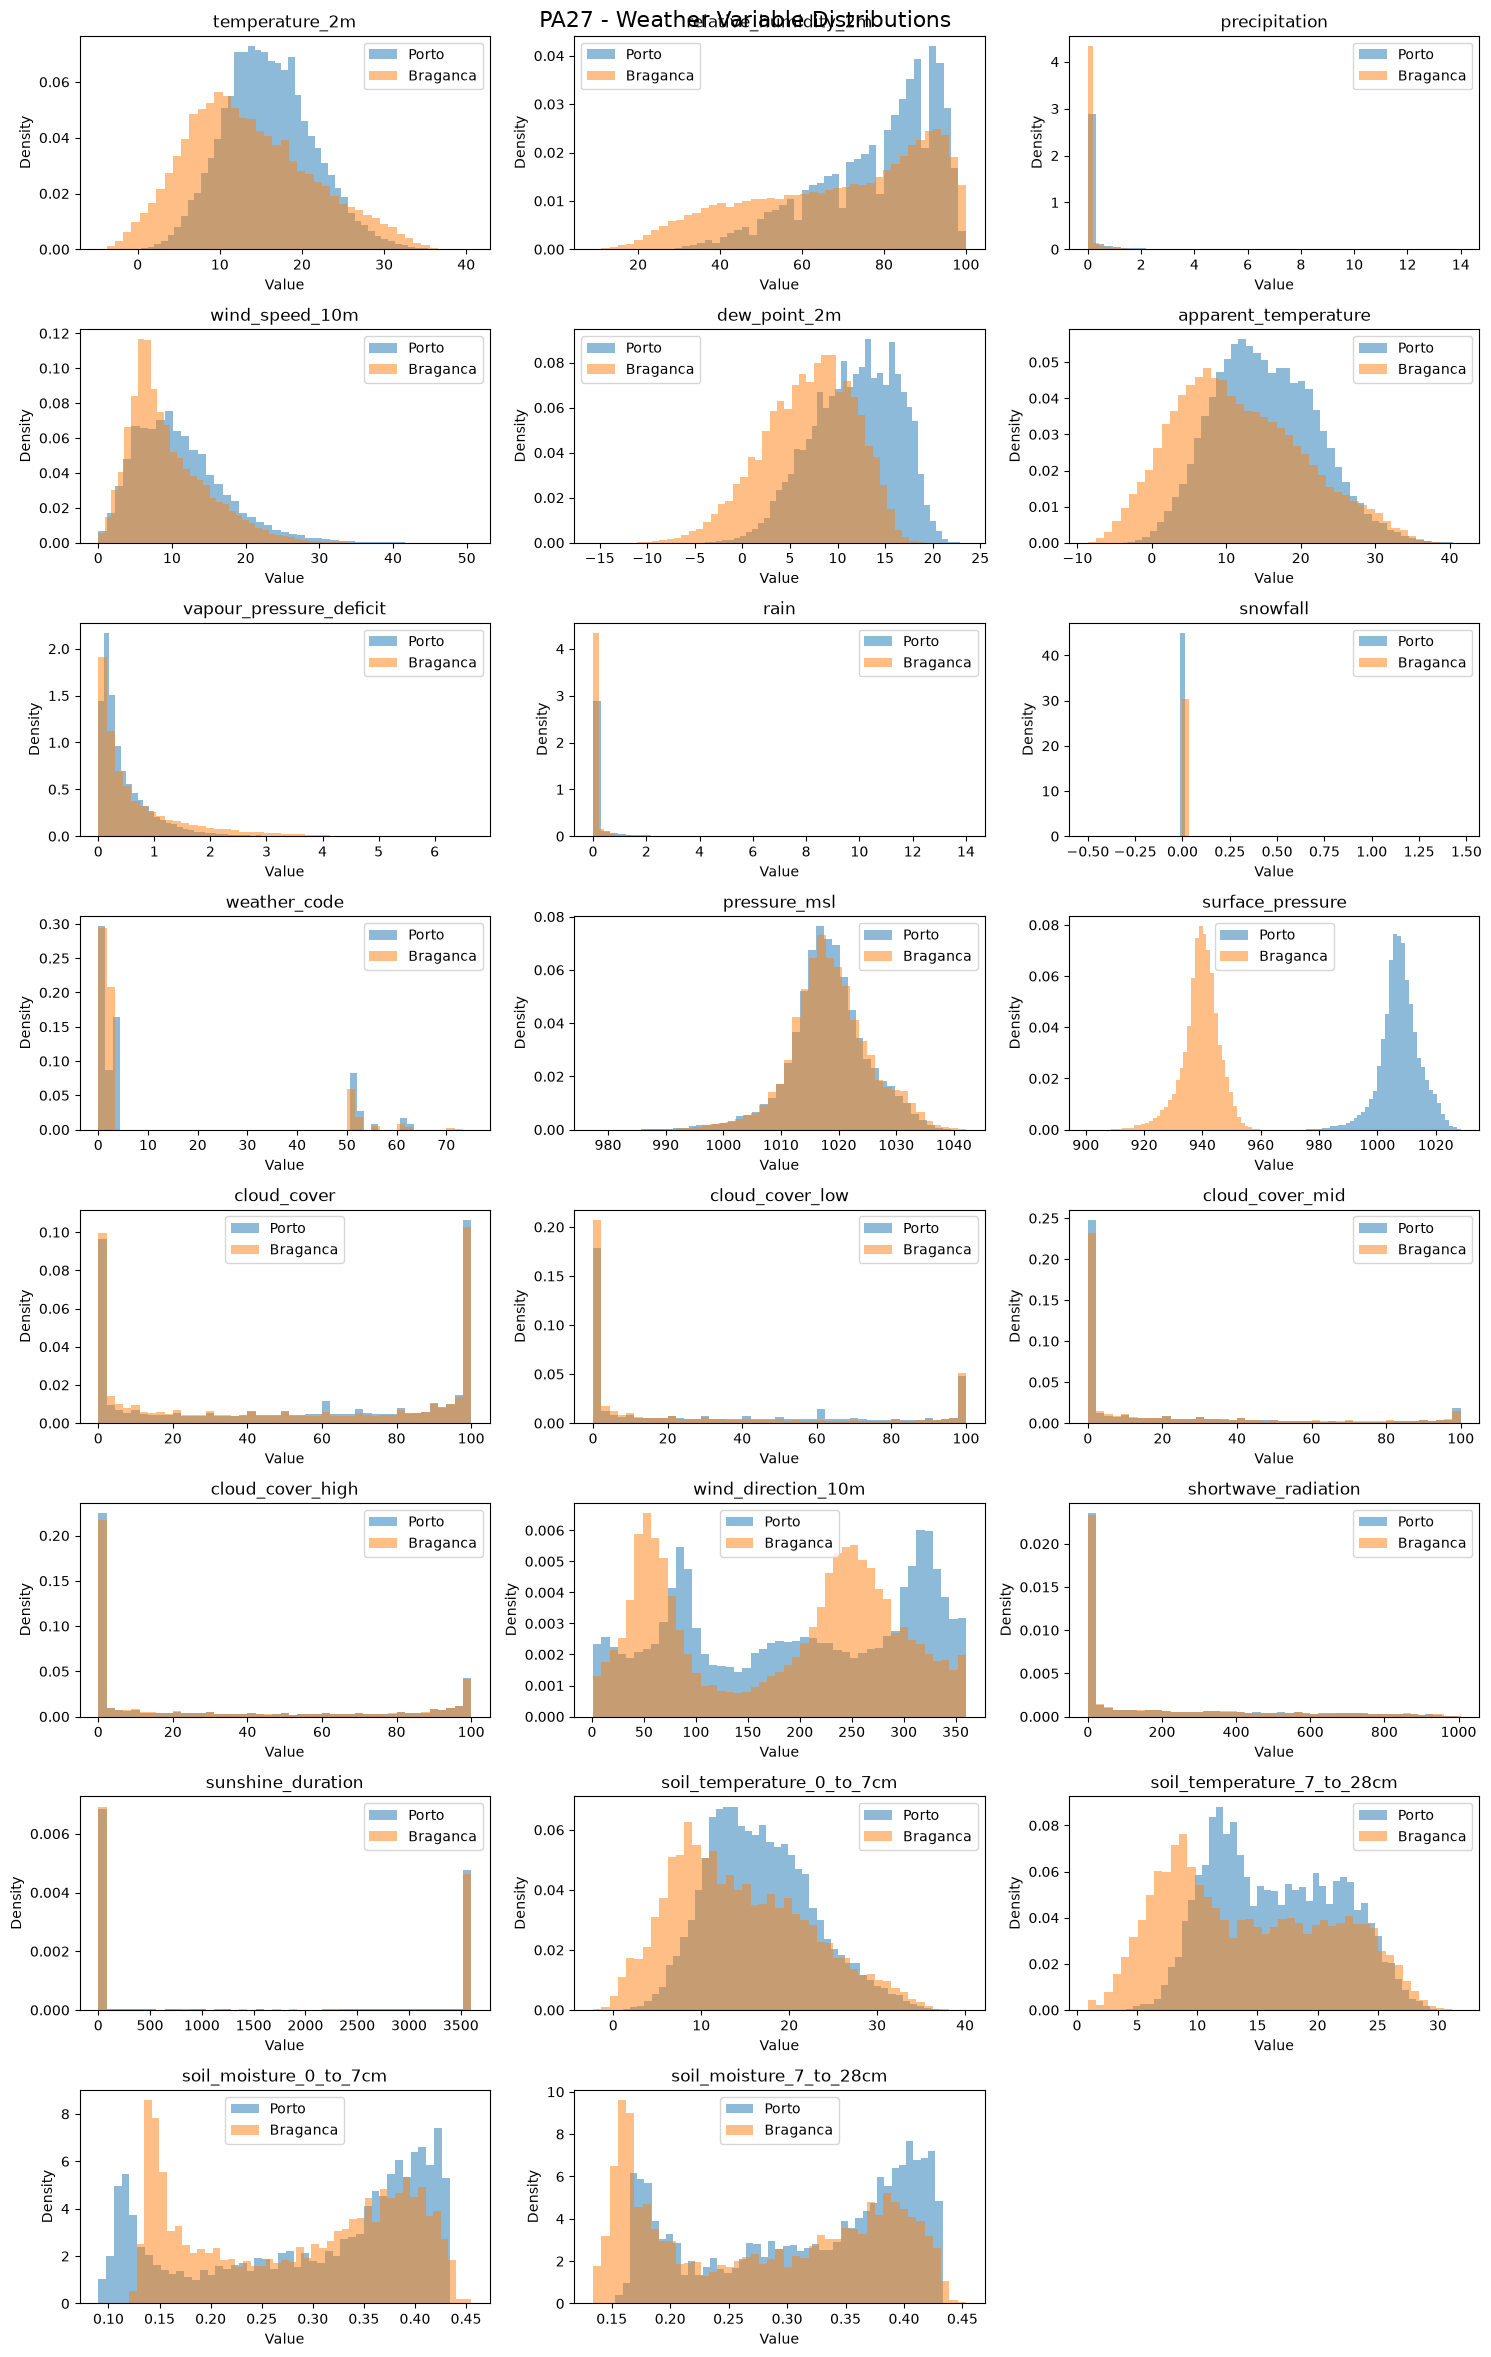

In [10]:
n_cols = 3
n_rows = math.ceil(len(weather) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, n_rows * 3)
)

for ax, var in zip(axes.flat, weather):

    for city, df in cities.items():
        ax.hist(
            df[var].dropna(),
            bins=45,
            alpha=0.5,
            density=True,
            label=city
        )

    ax.set_title(var)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend()

# Remove empty subplots
for ax in axes.flat[len(weather):]:
    ax.set_visible(False)

fig.suptitle("PA27 - Weather Variable Distributions", fontsize=16)
fig.tight_layout()

fig.savefig(
    FIG_DIR / "02_weather_distributions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


## 3. Correlations

### 3.1. Correlation Between Weather Variables

We used Pearson correlation coefficients to identify relationships between meteorological variables and detect potential multicollinearity, which helps us examine redundancy and support feature selection.

`weather_code` and `wind_direction_10m` are displayed in the correlation
matrix for completeness because they are stored numerically. However, their
Pearson coefficients are not used for feature-selection decisions because
weather code is categorical and wind direction is circular.


Correlation Matrix - Porto


,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,dew_point_2m,apparent_temperature,vapour_pressure_deficit,rain,snowfall,weather_code,...,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_direction_10m,shortwave_radiation,sunshine_duration,soil_temperature_0_to_7cm,soil_temperature_7_to_28cm,soil_moisture_0_to_7cm,soil_moisture_7_to_28cm
temperature_2m,1.00,-0.60,-0.11,-0.04,0.78,0.98,0.78,-0.11,NaN,-0.18,...,-0.25,-0.24,-0.11,0.29,0.58,0.47,0.96,0.83,-0.67,-0.64
relative_humidity_2m,-0.60,1.00,0.22,-0.12,0.03,-0.49,-0.90,0.22,NaN,0.32,...,0.54,0.31,0.19,-0.04,-0.68,-0.60,-0.52,-0.27,0.35,0.30
precipitation,-0.11,0.22,1.00,0.41,0.02,-0.15,-0.18,1.00,NaN,0.68,...,0.35,0.51,0.24,0.06,-0.09,-0.12,-0.12,-0.15,0.28,0.23
wind_speed_10m,-0.04,-0.12,0.41,1.00,-0.13,-0.18,0.06,0.41,NaN,0.42,...,0.12,0.35,0.12,0.17,0.14,0.13,-0.02,-0.15,0.23,0.23
dew_point_2m,0.78,0.03,0.02,-0.13,1.00,0.84,0.25,0.02,NaN,0.02,...,0.09,-0.07,0.01,0.34,0.20,0.13,0.79,0.83,-0.56,-0.57
apparent_temperature,0.98,-0.49,-0.15,-0.18,0.84,1.00,0.71,-0.15,NaN,-0.21,...,-0.21,-0.26,-0.11,0.28,0.54,0.41,0.96,0.86,-0.70,-0.67
vapour_pressure_deficit,0.78,-0.90,-0.18,0.06,0.25,0.71,1.00,-0.18,NaN,-0.27,...,-0.43,-0.29,-0.17,0.11,0.69,0.54,0.72,0.49,-0.49,-0.43
rain,-0.11,0.22,1.00,0.41,0.02,-0.15,-0.18,1.00,NaN,0.68,...,0.35,0.51,0.24,0.06,-0.09,-0.12,-0.12,-0.15,0.28,0.23
snowfall,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_code,-0.18,0.32,0.68,0.42,0.02,-0.21,-0.27,0.68,NaN,1.00,...,0.49,0.66,0.31,0.10,-0.13,-0.15,-0.19,-0.22,0.39,0.33


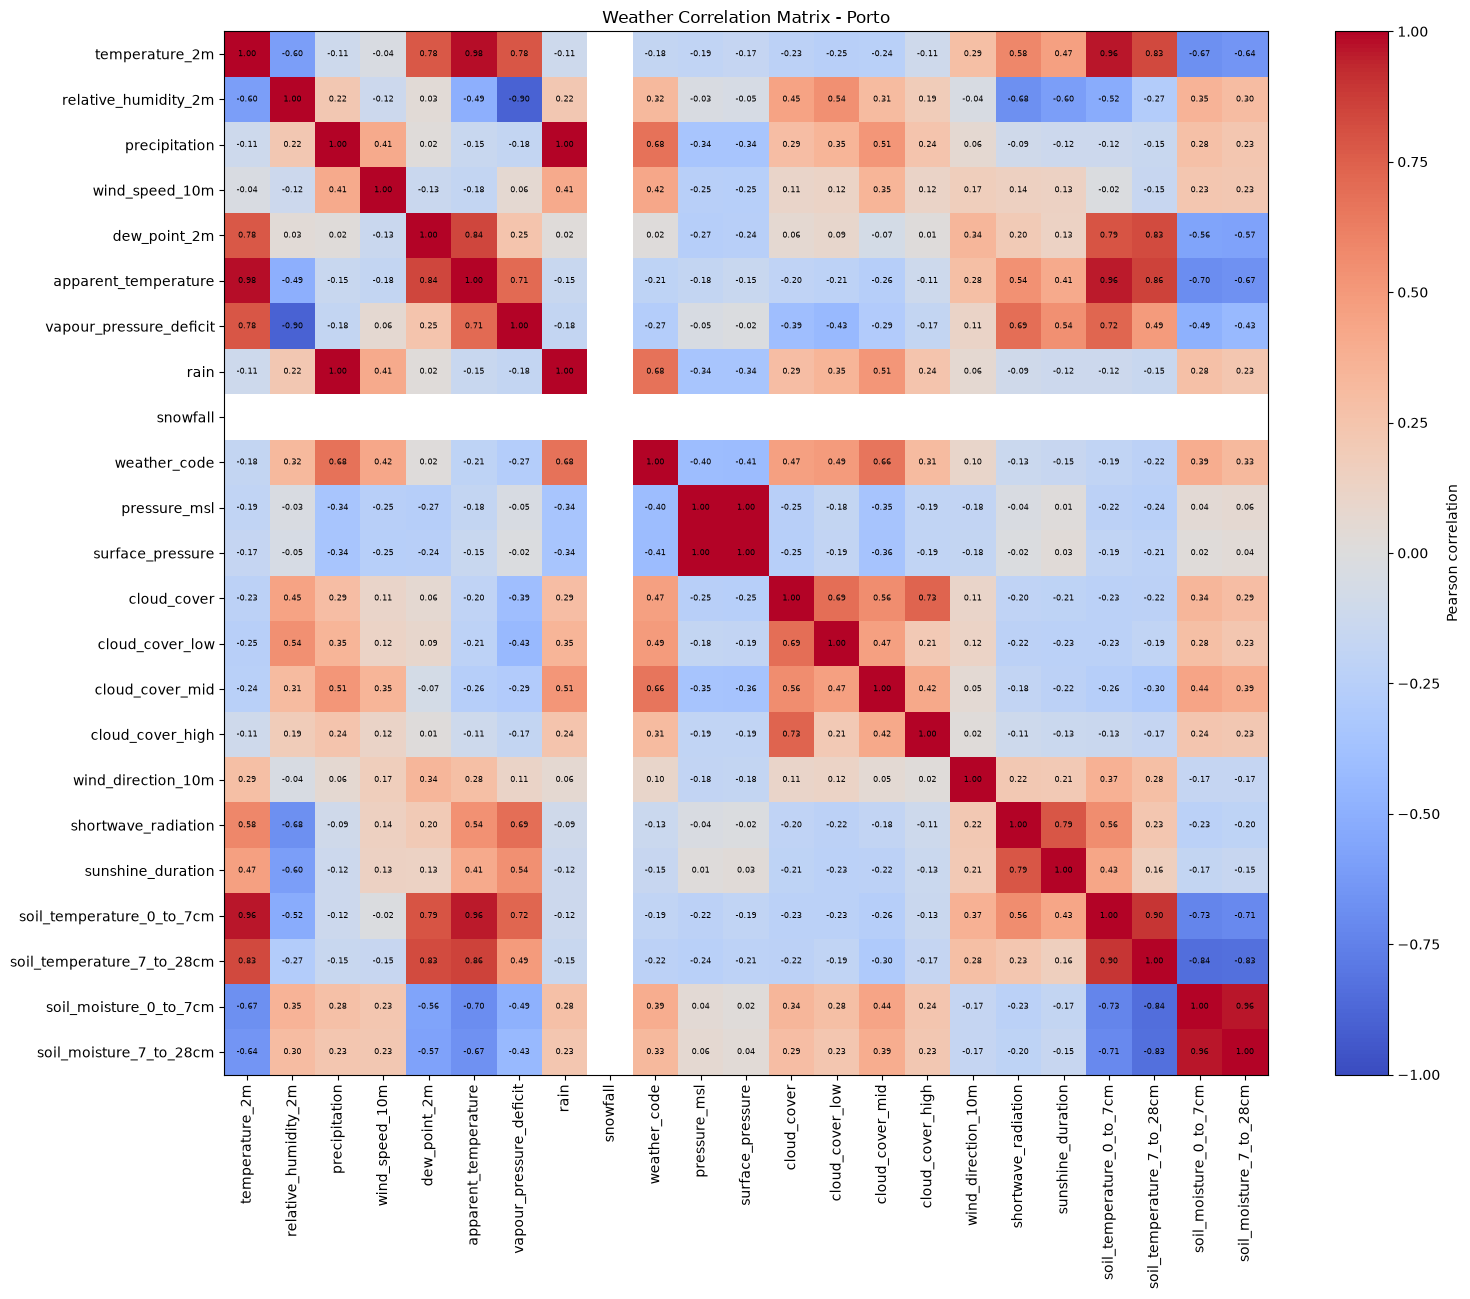


Correlation Matrix - Braganca


,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,dew_point_2m,apparent_temperature,vapour_pressure_deficit,rain,snowfall,weather_code,...,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_direction_10m,shortwave_radiation,sunshine_duration,soil_temperature_0_to_7cm,soil_temperature_7_to_28cm,soil_moisture_0_to_7cm,soil_moisture_7_to_28cm
temperature_2m,1.00,-0.77,-0.10,0.03,0.61,0.99,0.88,-0.10,-0.07,-0.18,...,-0.35,-0.21,-0.09,0.14,0.60,0.51,0.97,0.84,-0.69,-0.65
relative_humidity_2m,-0.77,1.00,0.25,-0.02,-0.01,-0.72,-0.88,0.25,0.07,0.37,...,0.56,0.35,0.20,-0.01,-0.64,-0.59,-0.73,-0.57,0.65,0.56
precipitation,-0.10,0.25,1.00,0.34,0.10,-0.12,-0.17,1.00,0.15,0.67,...,0.35,0.47,0.24,0.05,-0.08,-0.12,-0.11,-0.14,0.27,0.22
wind_speed_10m,0.03,-0.02,0.34,1.00,0.01,-0.06,0.03,0.34,0.08,0.39,...,0.32,0.29,0.09,0.15,0.14,0.11,0.03,-0.06,0.18,0.17
dew_point_2m,0.61,-0.01,0.10,0.01,1.00,0.68,0.23,0.11,-0.05,0.13,...,0.07,0.07,0.10,0.19,0.15,0.10,0.63,0.65,-0.32,-0.37
apparent_temperature,0.99,-0.72,-0.12,-0.06,0.68,1.00,0.84,-0.11,-0.08,-0.19,...,-0.35,-0.21,-0.08,0.13,0.59,0.48,0.97,0.85,-0.69,-0.66
vapour_pressure_deficit,0.88,-0.88,-0.17,0.03,0.23,0.84,1.00,-0.17,-0.05,-0.26,...,-0.43,-0.27,-0.16,0.09,0.67,0.55,0.85,0.67,-0.63,-0.56
rain,-0.10,0.25,1.00,0.34,0.11,-0.11,-0.17,1.00,0.12,0.66,...,0.35,0.47,0.24,0.05,-0.08,-0.12,-0.11,-0.14,0.27,0.21
snowfall,-0.07,0.07,0.15,0.08,-0.05,-0.08,-0.05,0.12,1.00,0.21,...,0.09,0.11,0.03,0.02,-0.03,-0.04,-0.06,-0.06,0.08,0.07
weather_code,-0.18,0.37,0.67,0.39,0.13,-0.19,-0.26,0.66,0.21,1.00,...,0.53,0.63,0.34,0.09,-0.09,-0.13,-0.19,-0.22,0.40,0.32


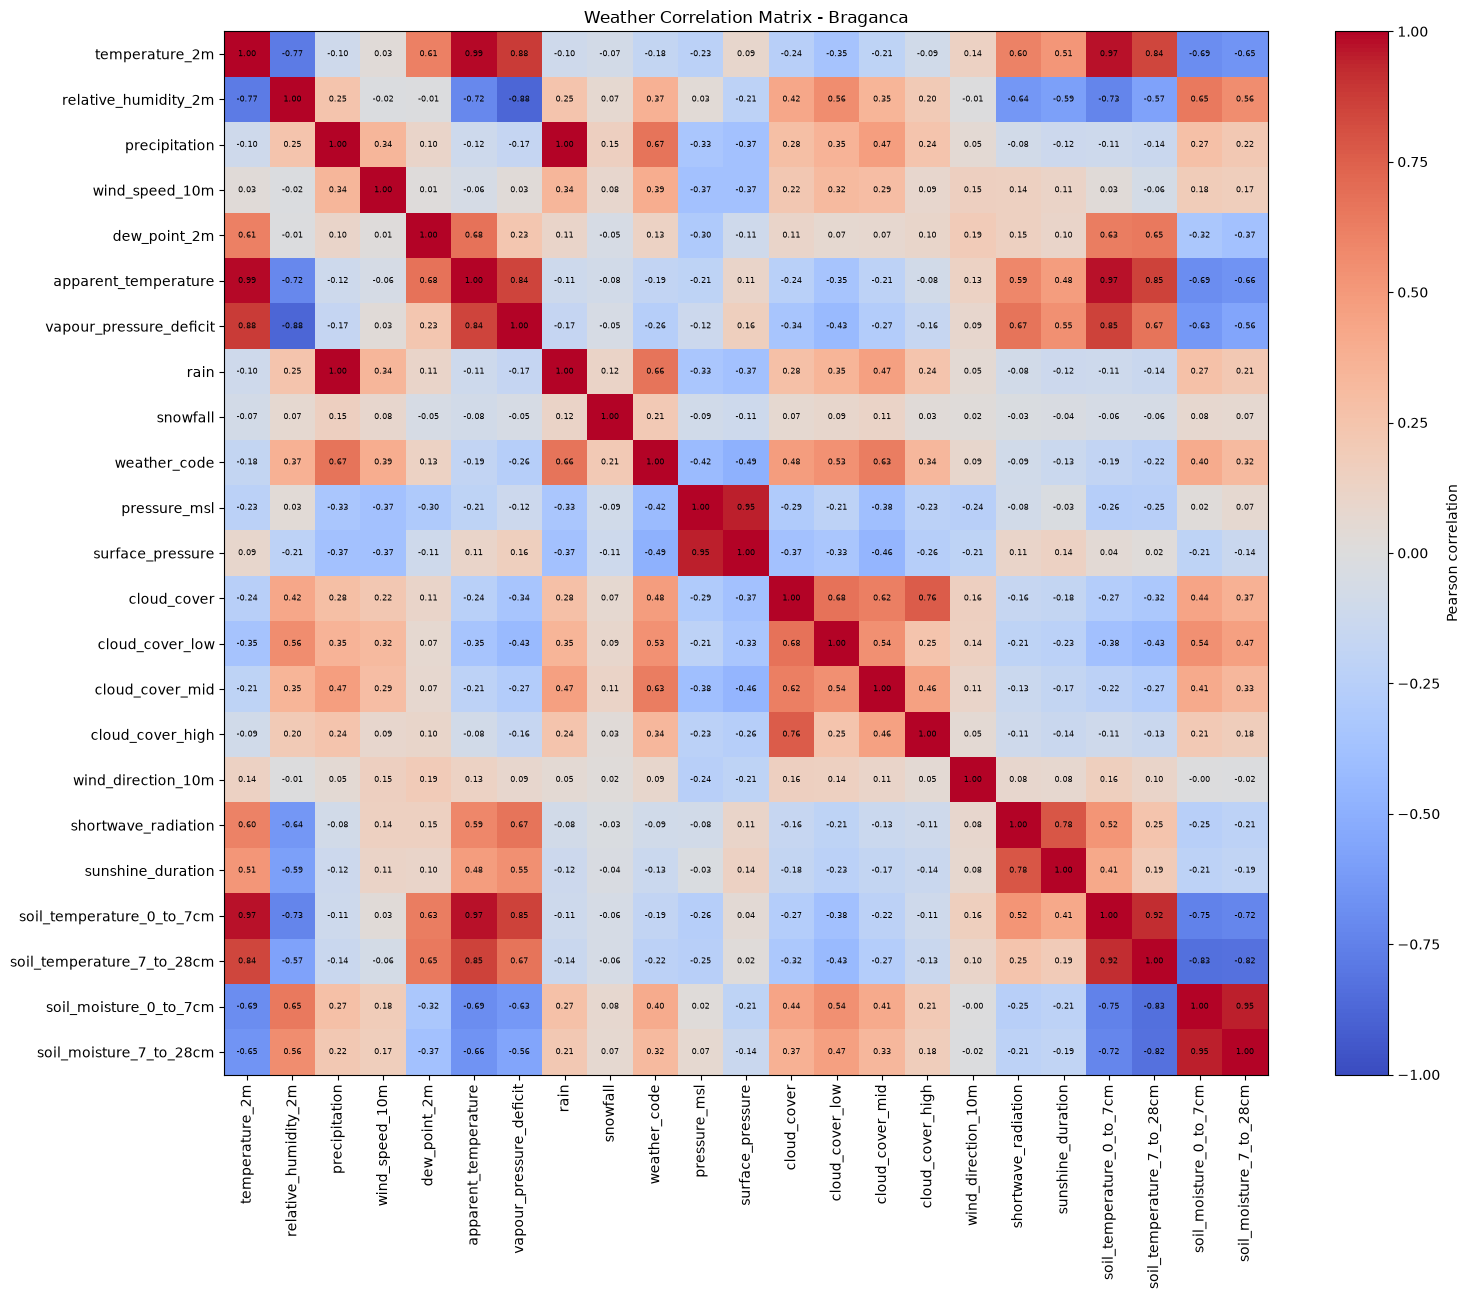

In [11]:
for city, df in warmup.items():

    # Calculate Pearson correlation
    corr = df[weather].corr(method="pearson")

    # Display correlation table
    print(f"\nCorrelation Matrix - {city}")
    display(corr.round(2))

    # Create heatmap
    fig, ax = plt.subplots(figsize=(16, 13))

    im = ax.imshow(
        corr,
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    # Variable names
    ax.set_xticks(range(len(weather)))
    ax.set_yticks(range(len(weather)))

    ax.set_xticklabels(weather, rotation=90)
    ax.set_yticklabels(weather)

    # Correlation values
    for i in range(len(weather)):
        for j in range(len(weather)):
            if not np.isnan(corr.iloc[i, j]):
                ax.text(
                    j, i,
                    f"{corr.iloc[i, j]:.2f}",
                    ha="center",
                    va="center",
                    fontsize=6
                )

    fig.colorbar(im, ax=ax, label="Pearson correlation")

    ax.set_title(f"Weather Correlation Matrix - {city}")

    plt.tight_layout()

    # Save heatmap
    fig.savefig(
        FIG_DIR / f"correlation_{city}.png",
        dpi=150,
        bbox_inches="tight"
    )

    # Save correlation table
    corr.round(2).to_csv(
        TAB_DIR / f"correlation_{city}.csv"
    )

    plt.show()
    plt.close(fig)

**Strong positive correlations:**
- `temperature_2m` and `apparent_temperature`: Porto (r = 0.98); Bragança (r = 0.99).
- `temperature_2m` and `soil_temperature_0_to_7cm`: Porto (r = 0.96); Bragança (r = 0.97).
- `precipitation` and `rain`: Porto (r = 1.00); Bragança (r = 1.00).
- `pressure_msl` and `surface_pressure`: Porto (r = 1.00); Bragança (r = 0.95).
- `soil_moisture_0_to_7cm` and `soil_moisture_7_to_28cm`: Porto (r = 0.96); Bragança (r = 0.95).

**Strong negative correlations:**
- `relative_humidity_2m` and `vapour_pressure_deficit`: Porto (r = -0.89); Bragança (r = -0.88).
- `temperature_2m` and `relative_humidity_2m`: Porto (r = -0.53); Bragança (r = -0.74).

For each pair of highly correlated variables, we examined scatterplots to visually assess whether the relationship was approximately linear or exhibited non-linear patterns.

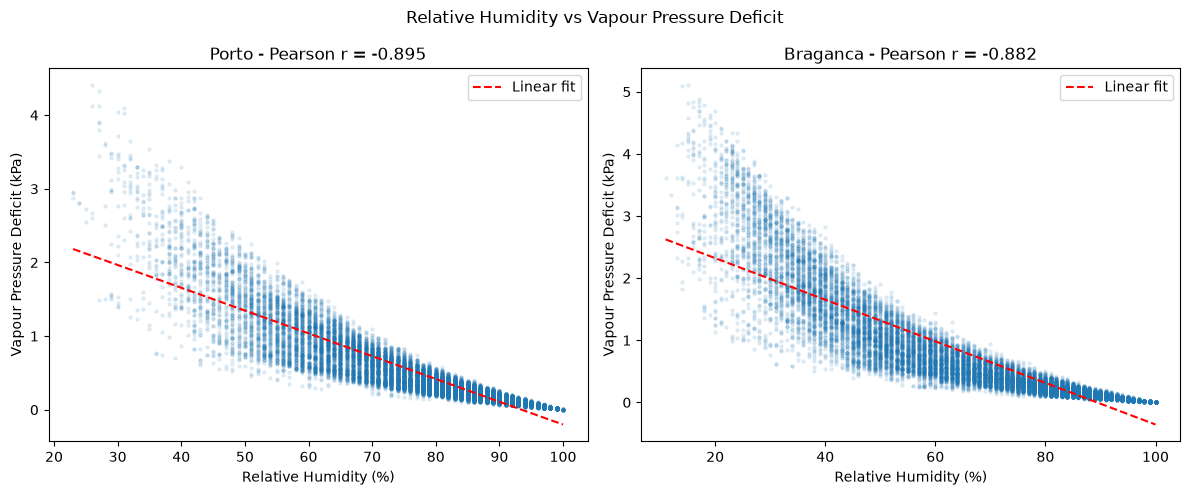

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (city, df) in zip(axes, warmup.items()):

    x = df["relative_humidity_2m"]
    y = df["vapour_pressure_deficit"]

    # Scatterplot
    ax.scatter(x, y, alpha=0.1, s=5)

    # Linear regression line
    slope, intercept = np.polyfit(x, y, 1)

    ax.plot(
        np.sort(x),
        slope * np.sort(x) + intercept,
        "r--",
        label="Linear fit"
    )

    # Pearson correlation
    correlation = x.corr(y)

    ax.set_title(f"{city} - Pearson r = {correlation:.3f}")
    ax.set_xlabel("Relative Humidity (%)")
    ax.set_ylabel("Vapour Pressure Deficit (kPa)")
    ax.legend()

plt.suptitle("Relative Humidity vs Vapour Pressure Deficit")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "humidity_vs_vpd.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


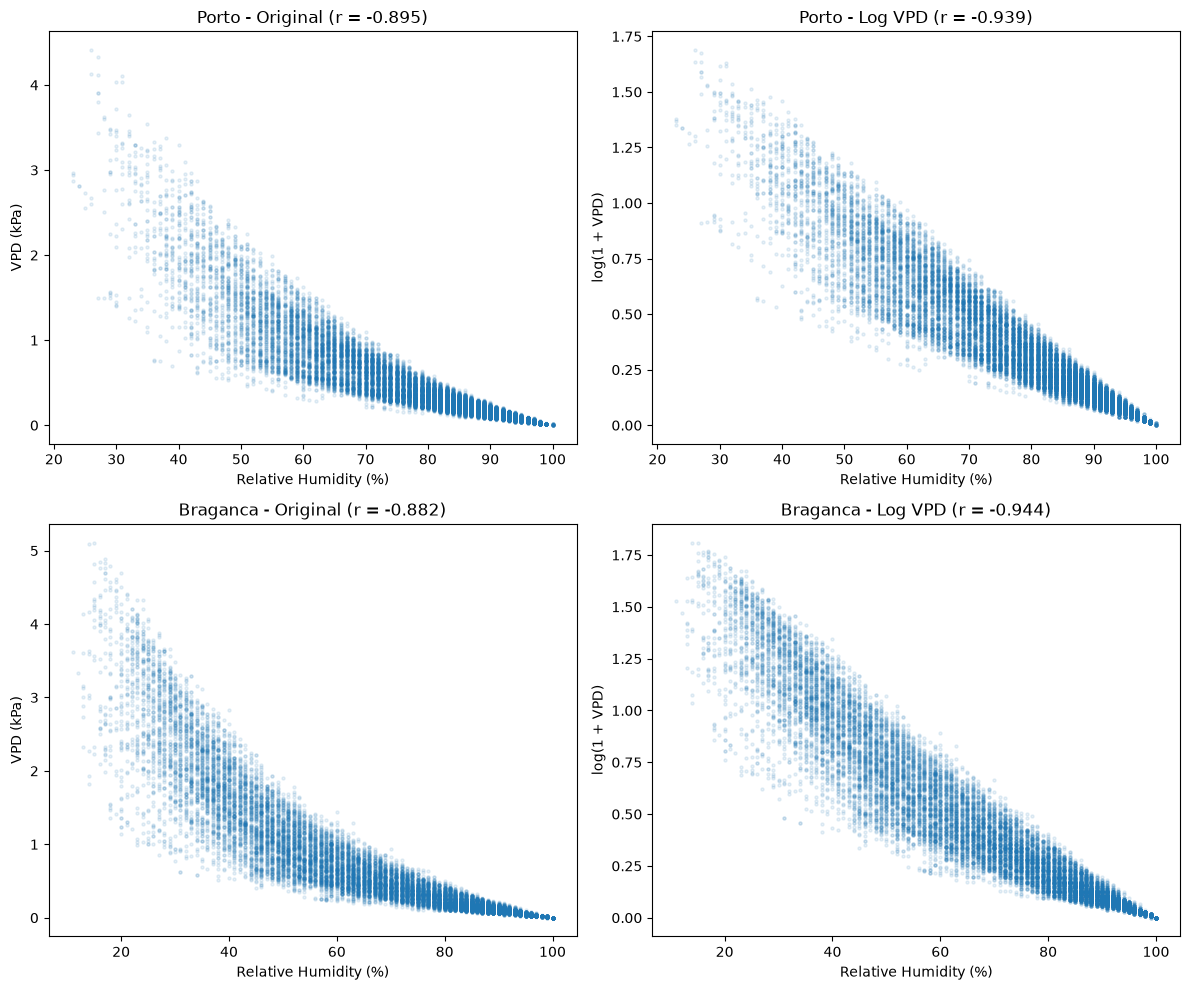

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, (city, df) in enumerate(warmup.items()):

    x = df["relative_humidity_2m"]
    y = df["vapour_pressure_deficit"]

    # Original relationship
    axes[i, 0].scatter(x, y, alpha=0.1, s=5)
    axes[i, 0].set_title(
        f"{city} - Original (r = {x.corr(y):.3f})"
    )
    axes[i, 0].set_xlabel("Relative Humidity (%)")
    axes[i, 0].set_ylabel("VPD (kPa)")

    # Log-transformed VPD
    y_log = np.log1p(y)

    axes[i, 1].scatter(x, y_log, alpha=0.1, s=5)
    axes[i, 1].set_title(
        f"{city} - Log VPD (r = {x.corr(y_log):.3f})"
    )
    axes[i, 1].set_xlabel("Relative Humidity (%)")
    axes[i, 1].set_ylabel("log(1 + VPD)")

plt.tight_layout()
plt.show()


**Note:** VPD is `vapour_pressure_deficit`.

Initially, `relative_humidity_2m` and `vapour_pressure_deficit` showed a strong negative correlation, but the scatterplots revealed a nonlinear relationship and uneven dispersion. A log transformation was applied to VPD to investigate the relationship, improving the absolute Pearson correlation from 0.889 to 0.932 in Porto and from 0.876 to 0.940 in Bragança, although some nonlinearity remained. 

### 3.2. Correlation with the Target

Pearson correlation coefficients were calculated between lagged meteorological variables and the Cold Stress target (T3), using only the warm-up period to avoid future information leakage. This analysis assesses the strength and direction of linear relationships and supports feature selection before the evaluation phase.

In [14]:
for city, df in cities.items():

    warmup = get_warmup(df).copy()

    # Previous-hour weather variables
    X = warmup[weather].shift(1)
    X = X.dropna()

    # Cold Stress at the current hour
    X[TARGET_COLUMN] = warmup[TARGET_COLUMN]

    correlations = (
        X.corr()[TARGET_COLUMN]
        .drop(TARGET_COLUMN)
        .sort_values(key=abs, ascending=False)
    )

    print(f"\nLagged feature correlations - {city}")

    display(correlations.to_frame("Correlation"))


Lagged feature correlations - Porto


,Correlation
temperature_2m,-0.526858
dew_point_2m,-0.514877
apparent_temperature,-0.513478
soil_temperature_0_to_7cm,-0.471361
soil_temperature_7_to_28cm,-0.411491
soil_moisture_7_to_28cm,0.244190
sunshine_duration,-0.241302
soil_moisture_0_to_7cm,0.241206
vapour_pressure_deficit,-0.233456
shortwave_radiation,-0.216109



Lagged feature correlations - Braganca


,Correlation
apparent_temperature,-0.718955
temperature_2m,-0.717360
soil_temperature_0_to_7cm,-0.690019
soil_temperature_7_to_28cm,-0.649492
dew_point_2m,-0.584421
soil_moisture_7_to_28cm,0.519240
soil_moisture_0_to_7cm,0.506335
relative_humidity_2m,0.494827
vapour_pressure_deficit,-0.466042
shortwave_radiation,-0.367525


**Weak correlations with Cold Stress in both locations:**
- `precipitation`: Porto (r = -0.037665); Bragança (r = 0.031926).
- `rain`: Porto (r = -0.037665); Bragança (r = 0.028953).
- `wind_speed_10m`: Porto (r = -0.026517); Bragança (r = -0.040778).
- `cloud_cover_high`: Porto (r = -0.057942); Bragança (r = 0.025932).

- `snowfall`: Bragança (r = 0.089324); Porto (r = NaN).

**Weak correlations with Cold Stress in one location:**
- `cloud_cover_low`: Porto (r = -0.035657).
- `cloud_cover_mid`: Porto (r = -0.029556).
- `cloud_cover`: Porto (r = -0.059787).
- `surface_pressure`: Bragança (r = -0.012005).

### 3.3. Feature Selection

Feature selection was performed using the warm-up period only.

Correlation with the target was used as diagnostic evidence, but a low
marginal Pearson correlation was not considered sufficient on its own to
discard a variable, since nonlinear or conditional relationships may still
be useful to the streaming classifiers.

Multicollinearity was used to identify redundant continuous predictors.
When two variables showed a very strong absolute correlation (|r| > 0.85),
one representative variable was retained based on interpretability,
assignment relevance, and operational meaning.

`weather_code` and `wind_direction_10m` were not treated as ordinary
continuous variables for feature selection because weather code is
categorical and wind direction is circular.

To ensure methodological comparability between Porto and Bragança, a common set of eleven meteorological predictors was adopted for both cities. The same feature names, order, temporal transformations and evaluation protocol are used in the individual and unified experiments.

**Feature decisions — Porto:**

- `apparent_temperature`: removed because it is highly redundant with
  `temperature_2m`. `temperature_2m` is retained because it is directly
  interpretable and is one of the assignment's core predictors.

- `vapour_pressure_deficit`: removed because it is strongly negatively
  correlated with `relative_humidity_2m`. Relative humidity is retained
  because it is directly interpretable and part of the core feature set.

- `rain`: removed because it is effectively redundant with `precipitation`.
  `precipitation` is retained.

- `surface_pressure`: removed because it is highly redundant with
  `pressure_msl`.

- `snowfall`: removed because it has zero variance in Porto.

- `soil_temperature_0_to_7cm`: removed because it is highly redundant with
  temperature-related predictors. `soil_temperature_7_to_28cm` is retained.

- `soil_moisture_0_to_7cm`: removed because it is highly correlated with
  `soil_moisture_7_to_28cm`. The latter is retained.

- `weather_code`: not included in the base numerical feature set because it
  is a categorical weather code rather than a continuous measurement.

- `wind_direction_10m`: not included in its raw degree representation because
  direction is circular. If used later, it should first be transformed into
  sine/cosine components.

- `cloud_cover`: retained as an overall measure of cloudiness. Although its
  marginal Pearson correlation with the target is weak, low linear correlation
  alone is not sufficient evidence for removal. The altitude-specific
  `cloud_cover_low`, `cloud_cover_mid`, and `cloud_cover_high` variables are
  excluded to avoid adding overlapping cloud information.

`precipitation` and `wind_speed_10m` are retained. Their weak marginal
Pearson correlation with the target is not sufficient evidence to discard
them.

In [15]:
weather_porto = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "dew_point_2m",
    "soil_temperature_7_to_28cm",
    "soil_moisture_7_to_28cm",
    "sunshine_duration",
    "shortwave_radiation",
    "pressure_msl",
    "cloud_cover",
]

**Feature decisions — Bragança:**

- `apparent_temperature`: removed because it is highly redundant with
  `temperature_2m`. Temperature is retained because it is directly
  interpretable and part of the core assignment feature set.

- `vapour_pressure_deficit`: removed because it is strongly redundant with
  `relative_humidity_2m`. Relative humidity is retained.

- `rain`: removed because it is effectively redundant with `precipitation`.
  `precipitation` is retained.

- `surface_pressure`: removed because it is highly redundant with
  `pressure_msl`.

- `soil_moisture_0_to_7cm`: removed because it is highly correlated with
  `soil_moisture_7_to_28cm`.

- `soil_temperature_0_to_7cm`: removed because it is strongly correlated
  with the deeper soil-temperature variable; `soil_temperature_7_to_28cm`
  is retained.

- `snowfall` : excluded from the predictive feature set to ensure consistency with Porto. Although snowfall is non-constant and meteorologically meaningful in Bragança, it is retained only for descriptive analysis. Both cities therefore use the same eleven predictors, ensuring a standardized comparison between individual and joint learning protocols.

- `weather_code`: not included in the base numerical feature set because it
  represents categorical weather conditions.

- `wind_direction_10m`: not included in its raw degree representation because
  wind direction is circular.

- `cloud_cover`: retained as an overall measure of cloudiness. The
  altitude-specific `cloud_cover_low`, `cloud_cover_mid`, and
  `cloud_cover_high` variables are excluded to avoid adding overlapping
  cloud information.

`precipitation` and `wind_speed_10m` are retained despite their weak marginal
Pearson correlations.

In [16]:
weather_braganca = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "dew_point_2m",
    "soil_temperature_7_to_28cm",
    "soil_moisture_7_to_28cm",
    "sunshine_duration",
    "shortwave_radiation",
    "pressure_msl",
    "cloud_cover",
]

assert weather_porto == weather_braganca

### 3.4. Warm-up Temporal Dependence for Window Design

To support the temporal-window choices without using evaluation data,
temporal dependence is inspected at several hourly lags using only the
2016–2017 warm-up period.

The analysis is diagnostic rather than an optimisation procedure: the
window sizes are not selected by maximising a correlation value.

In [17]:
warmup_cities = {
    city: get_warmup(df)
    for city, df in cities.items()
}

In [18]:
window_lags = [
    1,
    3,
    6,
    12,
    24,
]

window_rows = []

for city, df in warmup_cities.items():

    data = (
        df
        .sort_values(
            "timestamp_utc"
        )
        .reset_index(
            drop=True
        )
    )

    for lag in window_lags:

        window_rows.append({
            "city":
                city,

            "lag_hours":
                lag,

            "temperature_autocorrelation":
                data[
                    "temperature_2m"
                ].autocorr(
                    lag=lag
                ),

            "cold_stress_autocorrelation":
                data[
                    TARGET_COLUMN
                ]
                .astype(float)
                .autocorr(
                    lag=lag
                ),
        })


window_diagnostics = (
    pd.DataFrame(
        window_rows
    )
)

display(
    window_diagnostics.round(3)
)

window_diagnostics.to_csv(
    TAB_DIR
    / "03_window_diagnostics_warmup.csv",
    index=False,
)

,city,lag_hours,temperature_autocorrelation,cold_stress_autocorrelation
0,Porto,1,0.987,0.882
1,Porto,3,0.918,0.686
2,Porto,6,0.763,0.432
3,Porto,12,0.580,0.192
4,Porto,24,0.920,0.596
5,Braganca,1,0.988,0.913
6,Braganca,3,0.918,0.766
7,Braganca,6,0.753,0.594
8,Braganca,12,0.541,0.438
9,Braganca,24,0.946,0.741


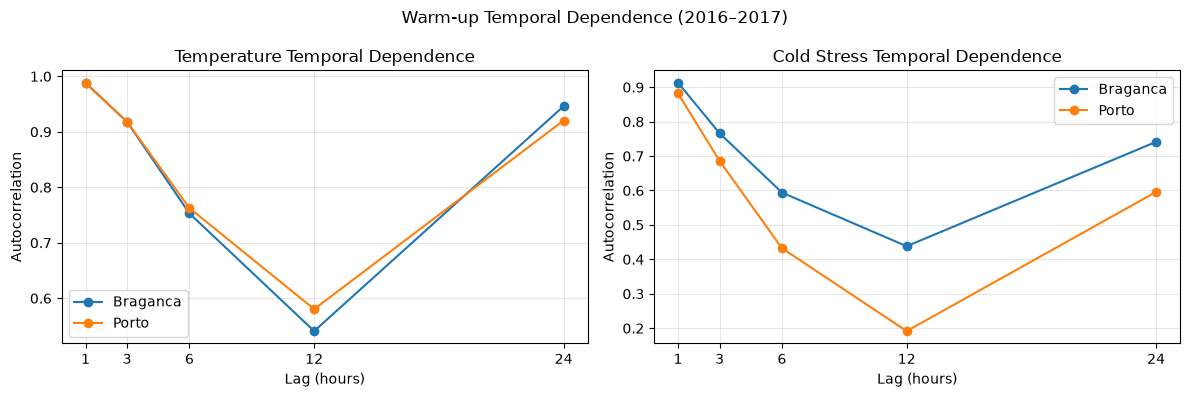

In [19]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
)

for city, data in (
    window_diagnostics
    .groupby("city")
):

    axes[0].plot(
        data["lag_hours"],
        data[
            "temperature_autocorrelation"
        ],
        marker="o",
        label=city,
    )

    axes[1].plot(
        data["lag_hours"],
        data[
            "cold_stress_autocorrelation"
        ],
        marker="o",
        label=city,
    )


axes[0].set_title(
    "Temperature Temporal Dependence"
)

axes[0].set_xlabel(
    "Lag (hours)"
)

axes[0].set_ylabel(
    "Autocorrelation"
)


axes[1].set_title(
    "Cold Stress Temporal Dependence"
)

axes[1].set_xlabel(
    "Lag (hours)"
)

axes[1].set_ylabel(
    "Autocorrelation"
)


for ax in axes:
    ax.set_xticks(
        window_lags
    )

    ax.grid(
        True,
        alpha=0.3,
    )

    ax.legend()


fig.suptitle(
    "Warm-up Temporal Dependence (2016–2017)"
)

fig.tight_layout()

fig.savefig(
    FIG_DIR
    / "03_window_temporal_dependence.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


### Common variables for comparative EDA

The `weather_global` subset is used for selected descriptive
comparisons between Porto and Bragança.

The predictive experiments use eleven identical meteorological
base predictors in both cities, defined separately in
`BASE_FEATURES` within `config/experiment.py`.

Representation A uses the eleven lagged predictors, while
Representation B extends them with four temporal features.

Snowfall remains available in the original weather data
for descriptive analysis but is excluded from predictive modelling.


In [20]:
weather_global = [
    "temperature_2m",
    "dew_point_2m",
    "soil_temperature_7_to_28cm",
    "soil_moisture_7_to_28cm",
    "relative_humidity_2m",
    "shortwave_radiation",
    "sunshine_duration",
    "pressure_msl",
]

| Variable | Definition | Unit |
|---|---|---|
| `temperature_2m` | Air temperature at 2 metres above ground level. | °C |
| `dew_point_2m` | Temperature at which the air becomes saturated with water vapour, measured at 2 metres above ground level. | °C |
| `relative_humidity_2m` | Percentage of water vapour in the air relative to its saturation capacity at the current temperature. | % |
| `soil_temperature_7_to_28cm` | Soil temperature at depths between 7 and 28 centimetres below ground level. | °C |
| `soil_moisture_7_to_28cm` | Volumetric water content of the soil between 7 and 28 centimetres below ground level. | m³/m³ |
| `sunshine_duration` | Duration of sunshine during the preceding hour, defined by direct solar irradiance exceeding 120 W/m². | s |
| `shortwave_radiation` | Average incoming shortwave solar radiation received on a horizontal surface during the preceding hour. | W/m² |
| `pressure_msl` | Atmospheric pressure adjusted to mean sea level. | hPa |

## 4. Temporal Evolution

Temporal evolution of the eight selected meteorological variables in Porto and Bragança over the period 2016–2025. 
To identify seasonal patterns, long-term trends, and differences between the two cities, the variables are aggregated at a monthly level using appropriate summary statistics, such as means and sums.

In [21]:
units = {
    "temperature_2m": "°C",
    "dew_point_2m": "°C",
    "relative_humidity_2m": "%",
    "soil_temperature_7_to_28cm": "°C",
    "soil_moisture_7_to_28cm": "m³/m³",
    "sunshine_duration": "hours/month",
    "shortwave_radiation": "W/m²",
    "pressure_msl": "hPa"
}

agg_methods = {
    "temperature_2m": "mean",
    "dew_point_2m": "mean",
    "relative_humidity_2m": "mean",
    "soil_temperature_7_to_28cm": "mean",
    "soil_moisture_7_to_28cm": "mean",
    "sunshine_duration": "sum",
    "shortwave_radiation": "mean",
    "pressure_msl": "mean"
}

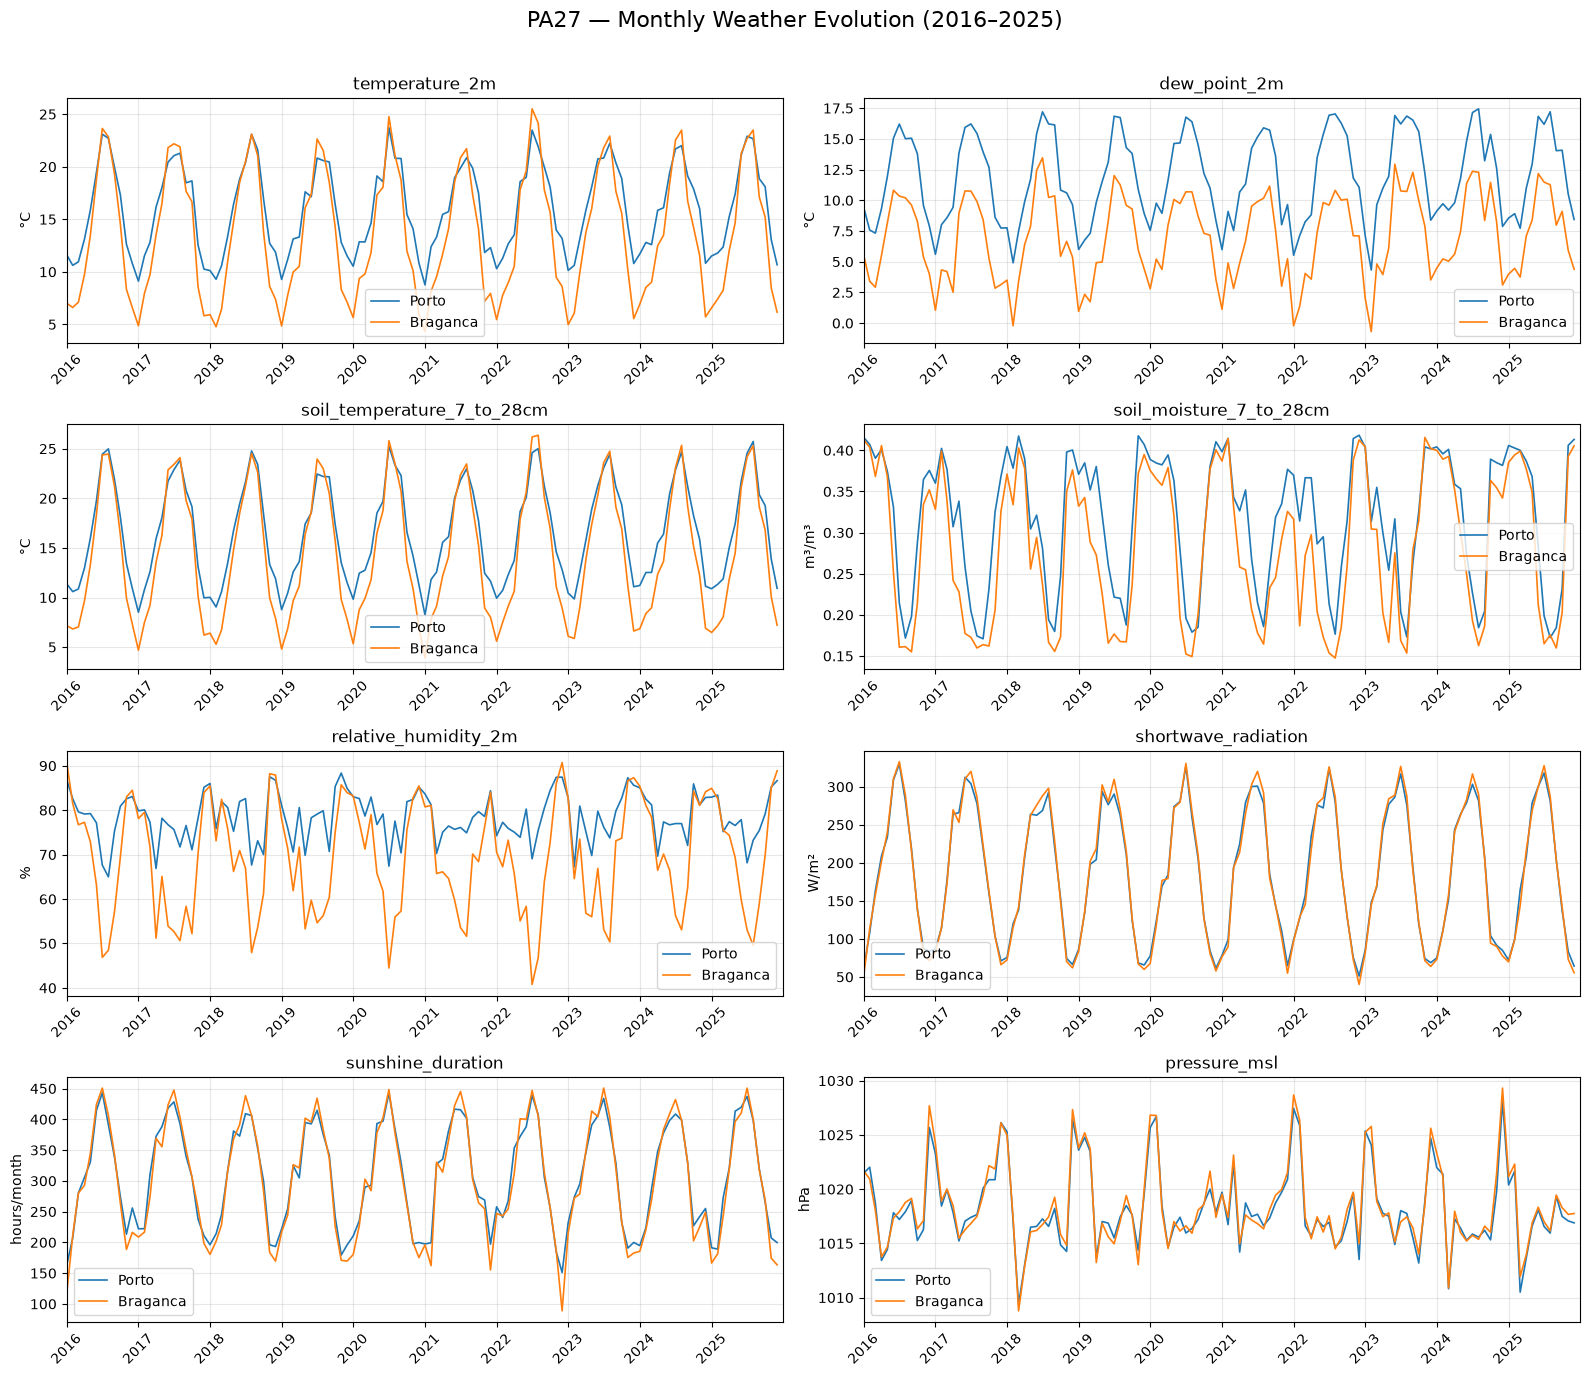

In [22]:
fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 14),
    sharex=True
)

axes = axes.flatten()

for name, df in cities.items():

    monthly = (
        df.assign(
            timestamp_utc=pd.to_datetime(df["timestamp_utc"])
        )
        .set_index("timestamp_utc")[weather_global]
        .resample("MS")
        .agg(agg_methods)
    )

    monthly["sunshine_duration"] /= 3600

    for ax, var in zip(axes, weather_global):
        ax.plot(
            monthly.index,
            monthly[var],
            label=name,
            linewidth=1.2
        )

for ax, var in zip(axes, weather_global):
    ax.set_title(var)
    ax.set_ylabel(units[var])
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x", labelbottom=True, rotation=45)

    ax.set_xlim(
        pd.Timestamp("2016-01-01"),
        pd.Timestamp("2025-12-31")
    )

fig.suptitle(
    "PA27 — Monthly Weather Evolution (2016–2025)",
    fontsize=16
)

fig.tight_layout(rect=[0, 0, 1, 0.97])

fig.savefig(
    FIG_DIR / "03_weather_evolution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Bragança has bigger temperature variations, with hotter summers and colder winters, while Porto has milder temperatures and higher humidity. 

Soil moisture generally decreases during summer as temperatures and solar radiation increase. 

Sunshine duration and shortwave radiation follow similar seasonal patterns in both locations, reaching their highest values during summer.

Atmospheric pressure shows similar fluctuations in both regions, without a clear seasonal pattern.

Overall, the graphs highlight the differences between Porto’s maritime climate and Bragança’s more continental climate, with the most noticeable differences occurring in temperature, humidity, and soil moisture.

## 5. Target frequency and Class Distribution

We compare the frequency of Cold Stress events in Porto and Bragança, focusing on the differences in target distribution and potential class imbalance that may affect model performance.

,city,n_hours,cold_hours,non_cold_hours,cold_rate_pct
0,Porto,87672,7443,80229,8.49
1,Braganca,87672,25793,61879,29.42


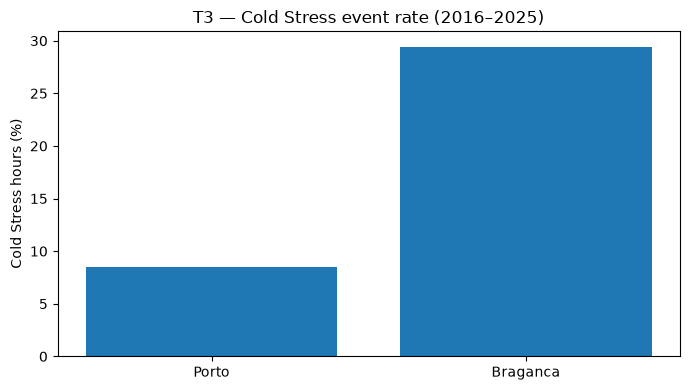

In [23]:
frequency = pd.DataFrame([
    {
        "city": name,
        "n_hours": len(df),
        "cold_hours": int(df[TARGET_COLUMN].sum()),
        "non_cold_hours": int((df[TARGET_COLUMN] == 0).sum()),
        "cold_rate_pct": df[TARGET_COLUMN].mean() * 100
    }
    for name, df in cities.items()
])

display(frequency.round(2))
frequency.to_csv(TAB_DIR / "04_target_frequency.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(frequency["city"], frequency["cold_rate_pct"])
ax.set_ylabel("Cold Stress hours (%)")
ax.set_title("T3 — Cold Stress event rate (2016–2025)")

fig.tight_layout()
fig.savefig(FIG_DIR / "04_target_frequency.png", dpi=150)
plt.show()

Cold Stress events are more than 3 times more frequent in Bragança (29.42%) than in Porto (8.49%). Both cities show class imbalance, particularly Porto, where Cold Stress represents a small minority of observations. 

## 6. Rolling/window behaviour

This shows how weather conditions and Cold Stress events change over time using rolling windows, helping identify temporal patterns, trends, and periods of increased Cold Stress.

**Note:** The 24-hour rolling rate measures the proportion of Cold Stress hours within each 24-hour window, including the current hour. These rates are then averaged weekly to make temporal patterns easier to visualize. For predictive features, only previous hours (up to t−1) would be used to avoid data leakage.

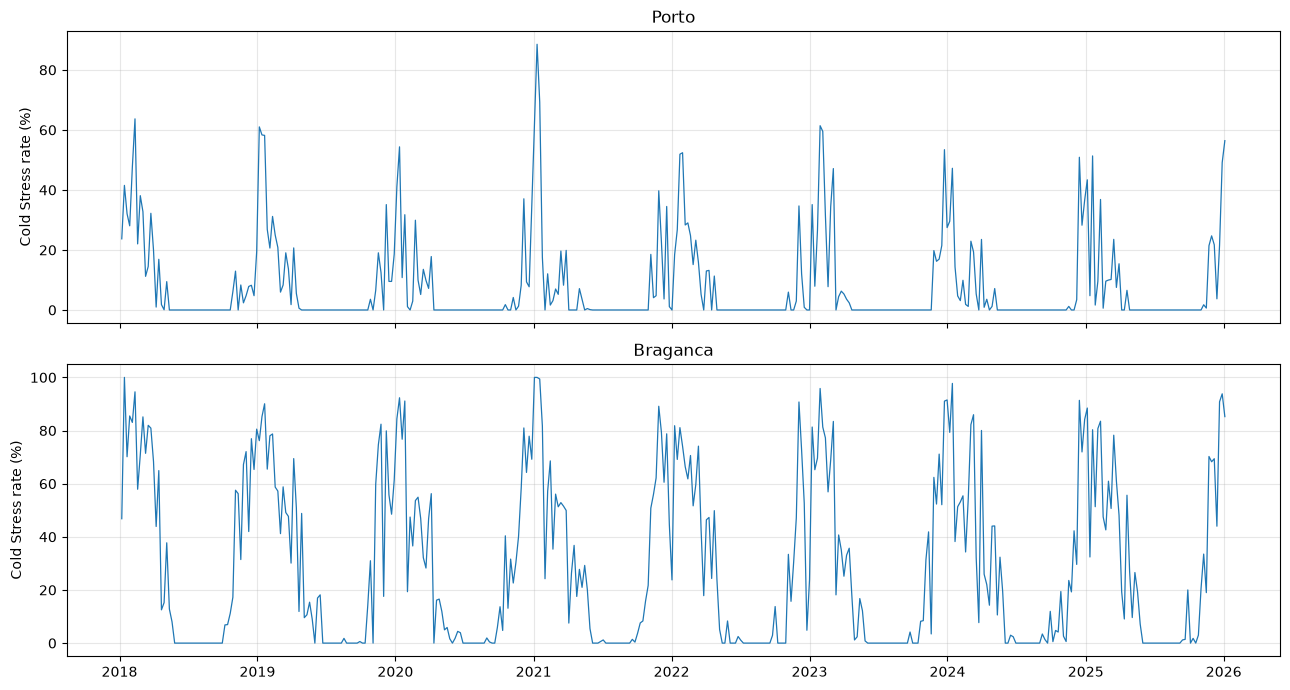

In [24]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(13, 7),
    sharex=True,
)

rolling_rows = []

for ax, (name, df) in zip(
    axes,
    evaluation.items(),
):

    rate = (
        df[TARGET_COLUMN]
        .rolling(
            window=24,
            min_periods=24,
        )
        .mean()
    )

    weekly_rate = (
        pd.DataFrame({
            "timestamp":
                df["timestamp_utc"],
            "rate":
                rate,
        })
        .set_index("timestamp")[
            "rate"
        ]
        .resample("W")
        .mean()
    )

    ax.plot(
        weekly_rate.index,
        weekly_rate * 100,
        linewidth=0.9,
    )

    ax.set_title(name)

    ax.set_ylabel(
        "Cold Stress rate (%)"
    )

    ax.grid(
        True,
        alpha=0.3,
    )

plt.tight_layout()
plt.show()

The rolling-window analysis shows a clear seasonal pattern, with Cold Stress events occurring mainly during winter and becoming rare in warmer months. Bragança experiences more frequent and sustained periods of Cold Stress, often reaching rates close to 100%, while Porto shows shorter and less frequent peaks.

## 7. Unusual / extreme observations

We will examine the distribution of selected weather variables in Porto and Bragança using boxplots to identify extreme values, potential outliers, and differences between the two cities.

In [25]:
extreme_rows = []

feature_sets = {
    "Porto-specific": {
        "Porto": weather_porto
    },
    "Braganca-specific": {
        "Braganca": weather_braganca
    }
}

for feature_set, city_features in feature_sets.items():

    for city, variables in city_features.items():

        df = cities[city]

        for var in variables:
            low, high = df[var].quantile([0.01, 0.99])

            extreme_rows.append({
                "feature_set": feature_set,
                "city": city,
                "variable": var,
                "min": df[var].min(),
                "p01": low,
                "p99": high,
                "max": df[var].max(),
                "below_p01": int((df[var] < low).sum()),
                "above_p99": int((df[var] > high).sum())
            })

extremes = pd.DataFrame(extreme_rows)

# Display results by feature set
for feature_set in feature_sets:
    print(f"\n{feature_set}")
    display(
        extremes[
            extremes["feature_set"] == feature_set
        ].round(2)
    )

# Export all results
extremes.to_csv(
    TAB_DIR / "06_extreme_values.csv",
    index=False
)


Porto-specific


,feature_set,city,variable,min,p01,p99,max,below_p01,above_p99
0,Porto-specific,Porto,temperature_2m,0.40,4.60,29.60,37.00,865,835
1,Porto-specific,Porto,relative_humidity_2m,18.00,38.00,98.00,100.00,732,616
2,Porto-specific,Porto,precipitation,0.00,0.00,2.60,14.00,0,839
3,Porto-specific,Porto,wind_speed_10m,0.00,1.40,29.70,50.60,848,859
4,Porto-specific,Porto,dew_point_2m,-4.60,1.20,19.80,23.50,836,825
5,Porto-specific,Porto,soil_temperature_7_to_28cm,4.10,7.30,27.20,29.90,857,814
6,Porto-specific,Porto,soil_moisture_7_to_28cm,0.15,0.17,0.43,0.43,731,667
7,Porto-specific,Porto,sunshine_duration,0.00,0.00,3600.00,3600.00,0,0
8,Porto-specific,Porto,shortwave_radiation,0.00,0.00,925.00,999.00,0,876
9,Porto-specific,Porto,pressure_msl,977.40,998.50,1033.70,1039.50,869,863



Braganca-specific


,feature_set,city,variable,min,p01,p99,max,below_p01,above_p99
11,Braganca-specific,Braganca,temperature_2m,-4.80,-0.80,32.30,40.60,867,866
12,Braganca-specific,Braganca,relative_humidity_2m,9.00,22.00,99.00,100.00,840,497
13,Braganca-specific,Braganca,precipitation,0.00,0.00,2.00,9.40,0,831
14,Braganca-specific,Braganca,wind_speed_10m,0.00,1.30,25.60,40.00,837,860
15,Braganca-specific,Braganca,dew_point_2m,-15.70,-5.20,15.80,19.10,835,823
16,Braganca-specific,Braganca,soil_temperature_7_to_28cm,0.90,3.00,27.90,31.90,855,819
17,Braganca-specific,Braganca,soil_moisture_7_to_28cm,0.13,0.14,0.43,0.45,800,798
18,Braganca-specific,Braganca,sunshine_duration,0.00,0.00,3600.00,3600.00,0,0
19,Braganca-specific,Braganca,shortwave_radiation,0.00,0.00,936.00,1006.00,0,864
20,Braganca-specific,Braganca,pressure_msl,977.60,998.80,1034.90,1042.10,872,864


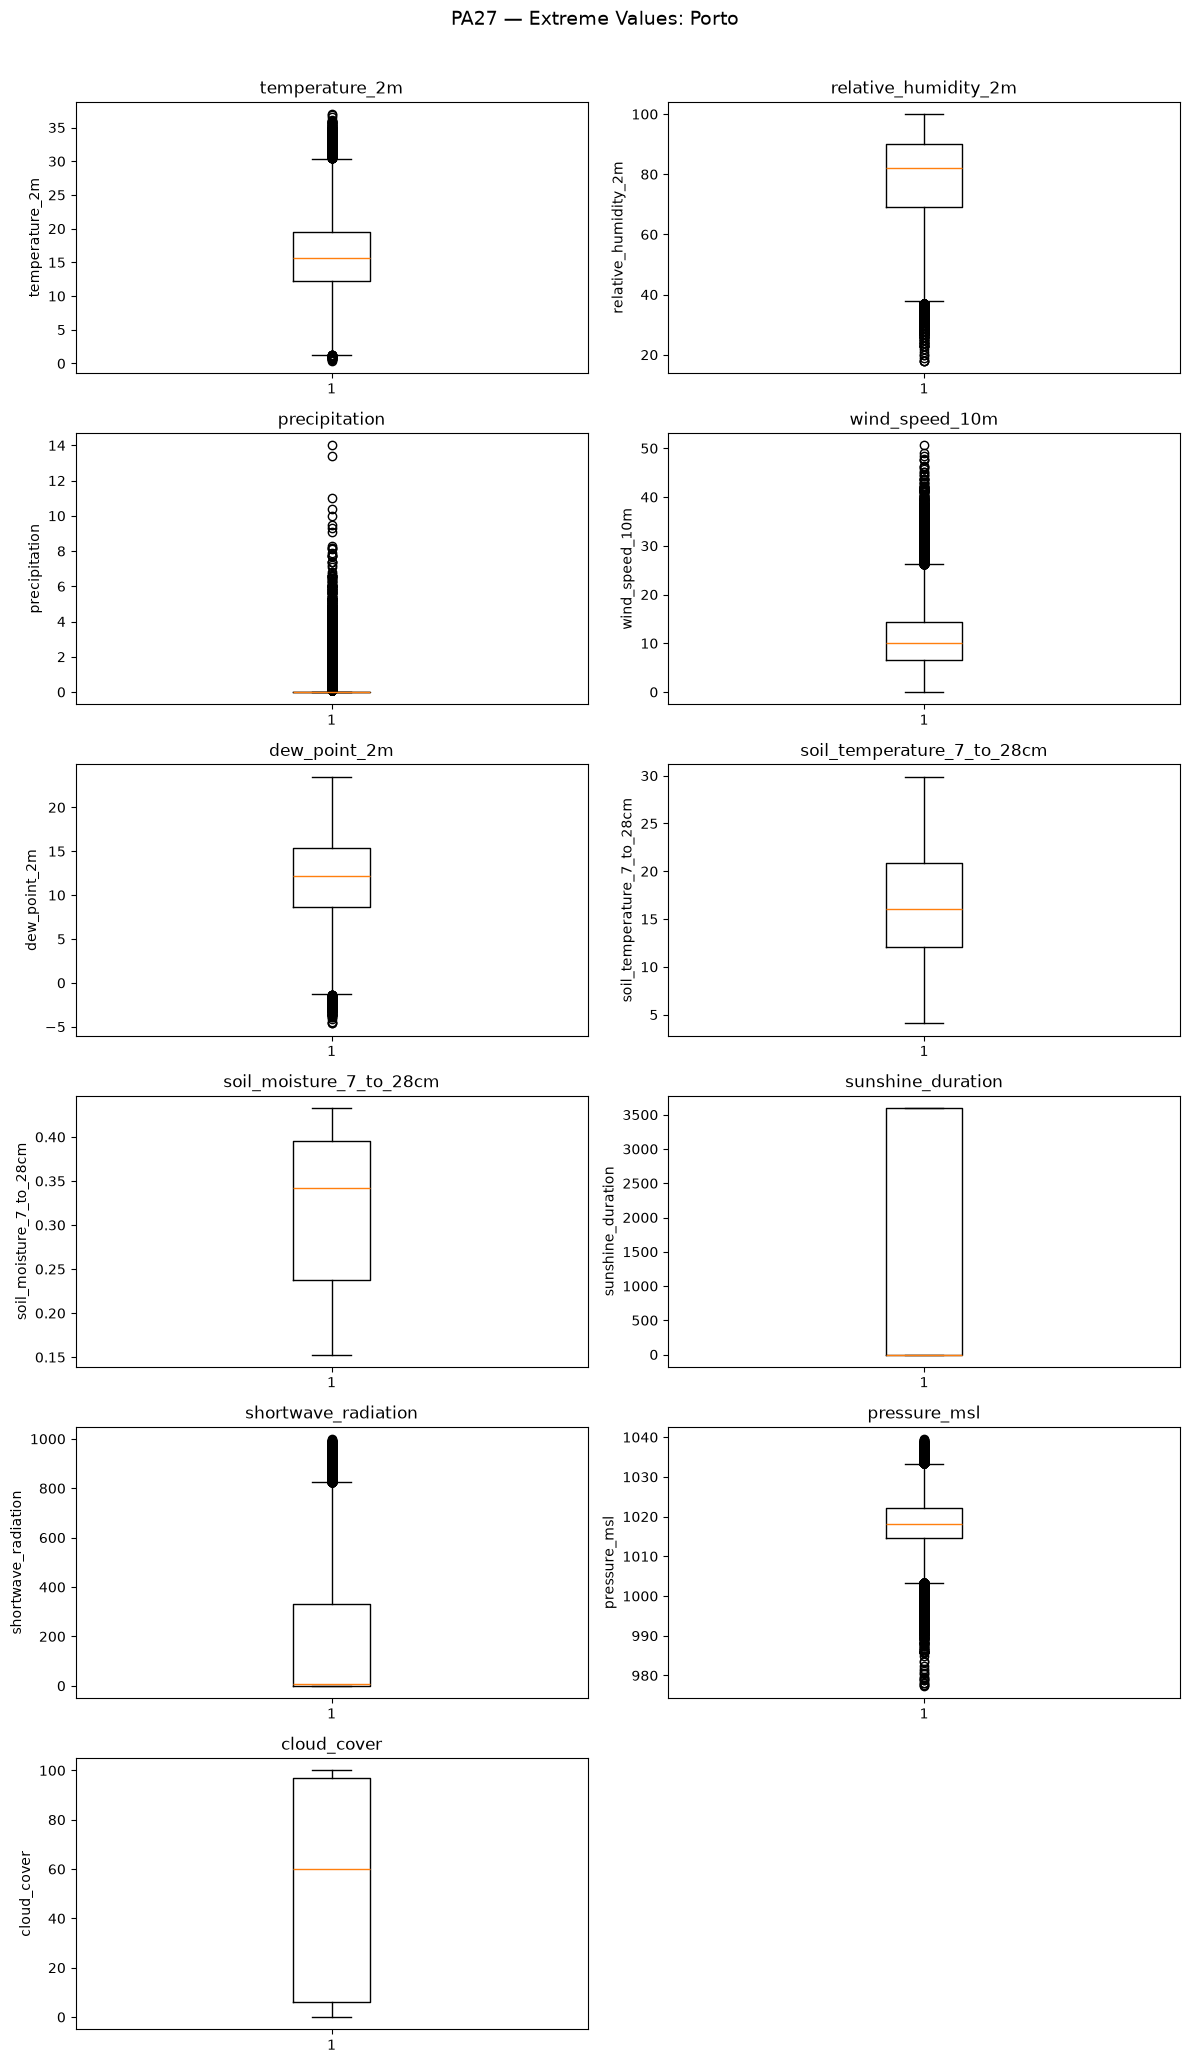

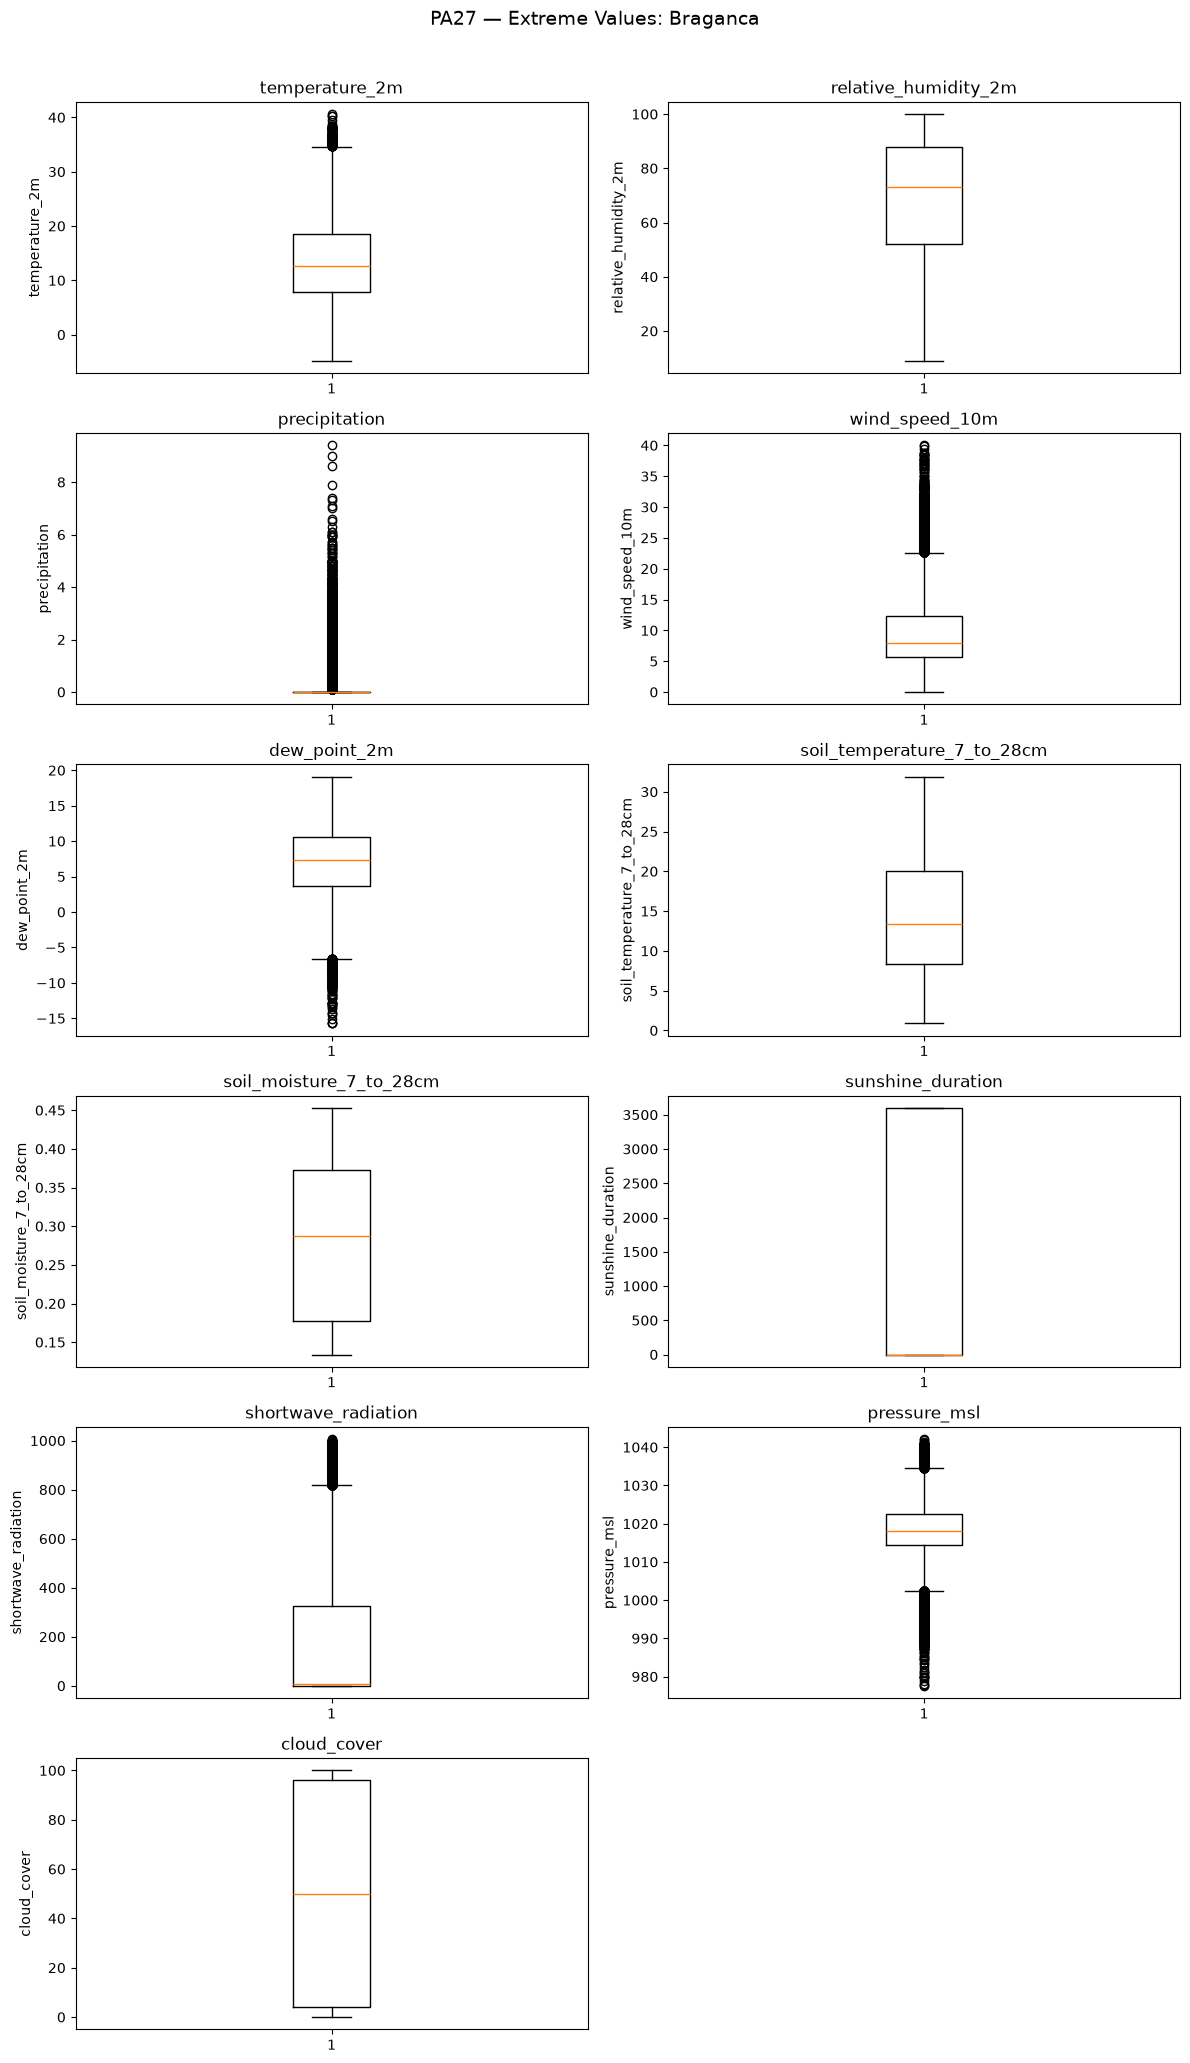

In [26]:
for feature_set, city_features in feature_sets.items():
    for city, variables in city_features.items():

        df = cities[city]
        variables = list(dict.fromkeys(variables))

        n_rows = (len(variables) + 1) // 2

        fig, axes = plt.subplots(
            n_rows, 2,
            figsize=(12, 3.5 * n_rows),
            squeeze=False
        )

        for ax, var in zip(axes.flatten(), variables):

            ax.boxplot(
                df[var].dropna(),
                orientation="vertical",
                showfliers=True
            )

            ax.set_title(var)
            ax.set_ylabel(var)

        # Hide unused subplots
        for ax in axes.flatten()[len(variables):]:
            ax.axis("off")

        fig.suptitle(
            f"PA27 — Extreme Values: {city}",
            fontsize=14
        )

        fig.tight_layout(rect=[0, 0, 1, 0.97])

        fig.savefig(
            FIG_DIR / f"06_extreme_boxplots_{city.lower()}.png",
            dpi=150,
            bbox_inches="tight"
        )

        plt.show()


The boxplots reveal several extreme observations, particularly in temperature, dew point, atmospheric pressure, and solar radiation.

Bragança shows greater temperature variability and lower minimum temperatures than Porto, consistent with its higher Cold Stress frequency. 

These extreme values reflect genuine weather conditions rather than data errors, so we will not be removing them yet.

## 8. Business Context

According to the Federal Highway Administration (FHWA, 2016), weather conditions play an important role in winter road maintenance, influencing decisions related to personnel, equipment, and preventive treatments. Our goal in this final section is to analyze the monthly frequency and duration of Cold Stress events in Porto and Bragança, which helps to identify periods of increased cold conditions and understand their potential impact on road-service planning.

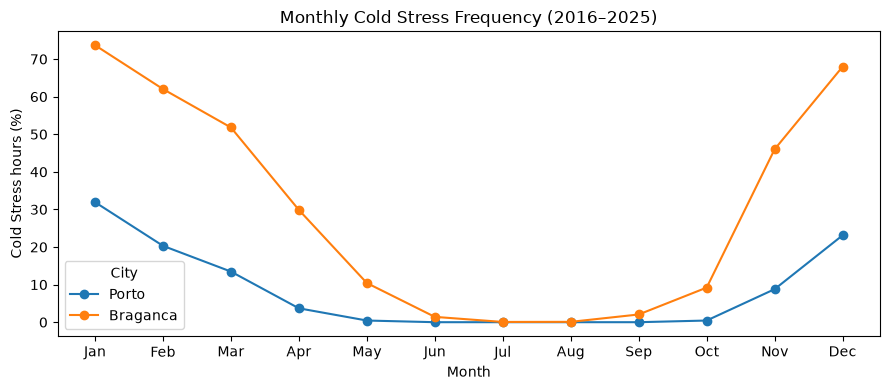

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
monthly_rows = []

for name, df in cities.items():
    profile = df.groupby(df["timestamp_utc"].dt.month)[TARGET_COLUMN].mean() * 100

    ax.plot(profile.index, profile.values, marker="o", label=name)

    monthly_rows.append(pd.DataFrame({
        "city": name,
        "month": profile.index,
        "cold_rate_pct": profile.values
    }))

ax.set_xticks(range(1, 13))
ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

ax.set_xlabel("Month")
ax.set_ylabel("Cold Stress hours (%)")
ax.set_title("Monthly Cold Stress Frequency (2016–2025)")
ax.legend(title="City")

fig.tight_layout()
fig.savefig(FIG_DIR / "07_monthly_cold_profile.png", dpi=150)
plt.show()

pd.concat(monthly_rows).to_csv(
    TAB_DIR / "07_monthly_cold_profile.csv",
    index=False
)


In [28]:
def cold_spell_lengths(series):
    runs = series.ne(series.shift()).cumsum()
    return series.groupby(runs).agg(["first", "size"]).query("first == 1")["size"]

spell_tables = []

for name, df in cities.items():
    # Ensure chronological order
    df = df.sort_values("timestamp_utc")

    lengths = cold_spell_lengths(df[TARGET_COLUMN])

    spell_tables.append({
        "city": name,
        "number_of_spells": len(lengths),
        "mean_duration_hours": lengths.mean(),
        "median_duration_hours": lengths.median(),
        "max_duration_hours": lengths.max(),
        "spells_24h_or_longer": int((lengths >= 24).sum())
    })

spell_summary = pd.DataFrame(spell_tables)

display(spell_summary.round(2))

spell_summary.to_csv(
    TAB_DIR / "07_cold_spell_duration.csv",
    index=False
)


,city,number_of_spells,mean_duration_hours,median_duration_hours,max_duration_hours,spells_24h_or_longer
0,Porto,787,9.46,9.0,46,4
1,Braganca,1605,16.07,13.0,526,145



| Column | Description |
|---|---|
| `number_of_spells` | Total number of Cold Stress episodes. |
| `mean_duration_hours` | Average duration of Cold Stress episodes, in hours. |
| `median_duration_hours` | Median duration of Cold Stress episodes, in hours. |
| `max_duration_hours` | Duration of the longest Cold Stress episode, in hours. |
| `spells_24h_or_longer` | Number of episodes lasting at least 24 consecutive hours. |


Cold Stress follows a clear seasonal pattern, with the highest frequencies occurring during winter, especially in Bragança. 

Between 2016 and 2025, Bragança recorded more frequent and longer Cold Stress episodes (1,605 events, averaging 16.07 hours) than Porto (787 events, averaging 9.46 hours). Bragança also experienced substantially more prolonged events lasting at least 24 hours (145 compared with 4 in Porto). 

Therefore, in the business context, it's possible to conclude that Bragança needs a greater sustained monitoring and winter road maintenance planning.